In [ ]:
!pip install -q numpy pandas matplotlib seaborn scikit-learn shap lightgbm joblib

import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

import lightgbm as lgb
import shap
import joblib

# Vérification des versions des dépendances
print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SHAP:", shap.__version__)
print("LightGBM:", lgb.__version__)
print("\nToutes les bibliothèques sont installées et chargées avec succès !")

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
SHAP: 0.54.1
LightGBM: 4.6.0

Toutes les bibliothèques sont installées et chargées avec succès !


In [ ]:
# Création des répertoires de sortie
folders = ["data", "results", "figures", "reports"]
for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Arborescence du projet créée :", folders)

# Chargement du jeu de données California Housing
df = pd.read_csv("sample_data/california_housing_train.csv")
df_test_raw = pd.read_csv("sample_data/california_housing_test.csv")

# Sauvegarde des données brutes dans le dossier data
df.to_csv("data/housing_train_raw.csv", index=False)
df_test_raw.to_csv("data/housing_test_raw.csv", index=False)

print(f"Dataset d'entraînement : {df.shape[0]} lignes, {df.shape[1]} colonnes.")
display(df.head())

Arborescence du projet créée : ['data', 'results', 'figures', 'reports']
Dataset d'entraînement : 17000 lignes, 9 colonnes.


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


=== Informations Générales sur le Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB

=== Statistiques Descriptives ===


,count,mean,std,min,25%,50%,75%,max
longitude,17000.0,-119.562108,2.005166,-124.3500,-121.790000,-118.4900,-118.000,-114.3100
latitude,17000.0,35.625225,2.137340,32.5400,33.930000,34.2500,37.720,41.9500
housing_median_age,17000.0,28.589353,12.586937,1.0000,18.000000,29.0000,37.000,52.0000
total_rooms,17000.0,2643.664412,2179.947071,2.0000,1462.000000,2127.0000,3151.250,37937.0000
total_bedrooms,17000.0,539.410824,421.499452,1.0000,297.000000,434.0000,648.250,6445.0000
population,17000.0,1429.573941,1147.852959,3.0000,790.000000,1167.0000,1721.000,35682.0000
households,17000.0,501.221941,384.520841,1.0000,282.000000,409.0000,605.250,6082.0000
median_income,17000.0,3.883578,1.908157,0.4999,2.566375,3.5446,4.767,15.0001
median_house_value,17000.0,207300.912353,115983.764387,14999.0000,119400.000000,180400.0000,265000.000,500001.0000



=== Analyse de l'Intégrité des Données ===
Valeurs manquantes par variable :
 longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
dtype: int64
Nombre de doublons stricts : 0
Valeurs sentinelles détectées : 0


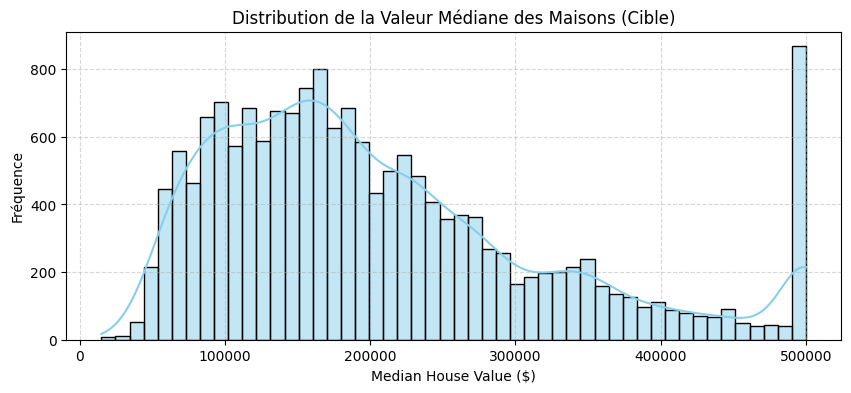

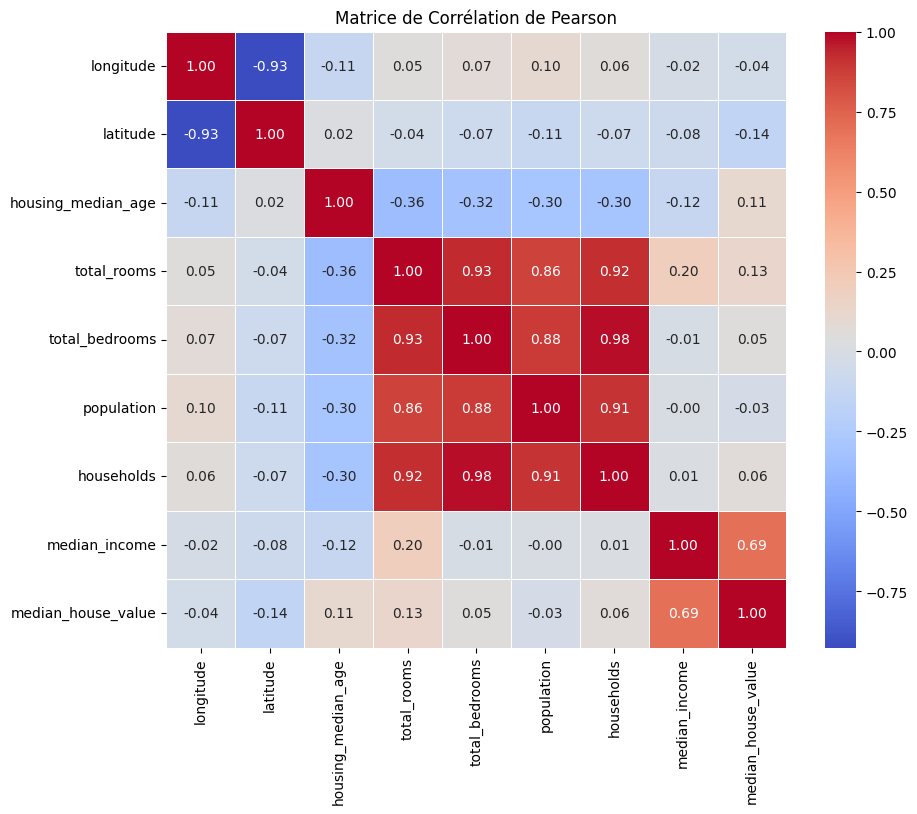

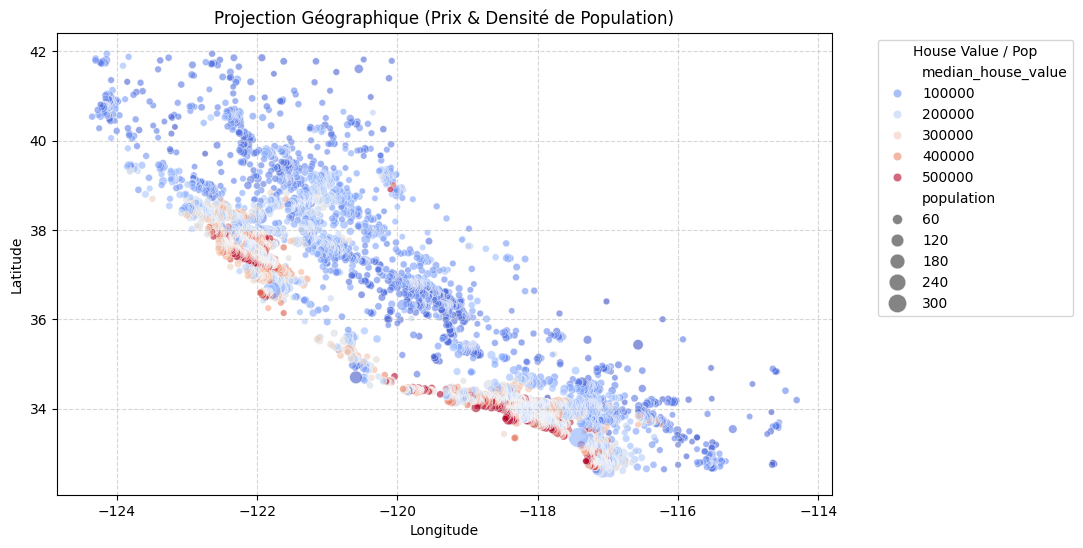

In [ ]:
print("=== Informations Générales sur le Dataset ===")
df.info()

print("\n=== Statistiques Descriptives ===")
display(df.describe().T)

print("\n=== Analyse de l'Intégrité des Données ===")
print("Valeurs manquantes par variable :\n", df.isnull().sum())
print("Nombre de doublons stricts :", df.duplicated().sum())

# Détection de valeurs sentinelles (-999, 999999, etc.)
sentinel_count = (df.isin([-1, -999, 999999])).sum().sum()
print("Valeurs sentinelles détectées :", sentinel_count)

# Visualisation 1 : Distribution de la variable cible
plt.figure(figsize=(10, 4))
sns.histplot(df["median_house_value"], kde=True, bins=50, color="skyblue")
plt.title("Distribution de la Valeur Médiane des Maisons (Cible)")
plt.xlabel("Median House Value ($)")
plt.ylabel("Fréquence")
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig("figures/01_target_distribution.png", bbox_inches='tight')
plt.show()

# Visualisation 2 : Carte thermochimique des corrélations de Pearson
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Matrice de Corrélation de Pearson")
plt.savefig("figures/02_correlation_matrix.png", bbox_inches='tight')
plt.show()

# Visualisation 3 : Projection géographique des prix et de la population
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="longitude",
    y="latitude",
    hue="median_house_value",
    size=df["population"] / 100,
    sizes=(20, 200),
    alpha=0.6,
    palette="coolwarm"
)
plt.title("Projection Géographique (Prix & Densité de Population)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="House Value / Pop", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig("figures/03_geographical_scatter.png", bbox_inches='tight')
plt.show()

In [ ]:
def apply_feature_engineering(data):
    df_feat = data.copy()
    # Nombre moyen de pièces par foyer
    df_feat["rooms_per_household"] = df_feat["total_rooms"] / df_feat["households"]
    # Ratio de chambres par rapport au nombre total de pièces
    df_feat["bedrooms_per_room"] = df_feat["total_bedrooms"] / df_feat["total_rooms"]
    # Nombre moyen d'habitants par foyer
    df_feat["population_per_household"] = df_feat["population"] / df_feat["households"]
    return df_feat

# Génération des nouvelles variables
df_prepared = apply_feature_engineering(df)
df_test_prepared = apply_feature_engineering(df_test_raw)

# Séparation des caractéristiques (X) et de la cible (y)
X = df_prepared.drop(columns=["median_house_value"])
y = df_prepared["median_house_value"]

# Split Train / Validation (80% / 20%)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalisation des variables numériques (nécessaire pour la régression Ridge)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Forme de X_train :", X_train.shape)
print("Forme de X_val   :", X_val.shape)
display(X_train.head(3))

Forme de X_train : (13600, 11)
Forme de X_val   : (3400, 11)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,population_per_household
4679,-118.07,33.81,22.0,2711.0,352.0,1305.0,368.0,8.5407,7.366848,0.129841,3.546196
2512,-117.63,33.50,12.0,3619.0,536.0,1506.0,492.0,7.2013,7.355691,0.148107,3.060976
993,-117.09,32.57,17.0,444.0,83.0,357.0,87.0,5.1478,5.103448,0.186937,4.103448


In [ ]:
models = {
    "Ridge Regression": (Ridge(alpha=1.0), True),
    "Random Forest": (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), False),
    "LightGBM": (lgb.LGBMRegressor(n_estimators=100, learning_rate=0.05, random_state=42, verbose=-1), False)
}

results = []

for name, (model, requires_scaling) in models.items():
    if requires_scaling:
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_val_scaled)
    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_val)

    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    mae = mean_absolute_error(y_val, predictions)
    r2 = r2_score(y_val, predictions)

    results.append({
        "Model": name,
        "RMSE ($)": round(rmse, 2),
        "MAE ($)": round(mae, 2),
        "R2 Score": round(r2, 4)
    })

comparison_df = pd.DataFrame(results).sort_values(by="RMSE ($)")
print("=== Tableau Comparatif des Performances sur le Jeu de Validation ===")
display(comparison_df)

comparison_df.to_csv("reports/model_comparison.csv", index=False)

=== Tableau Comparatif des Performances sur le Jeu de Validation ===


,Model,RMSE ($),MAE ($),R2 Score
2,LightGBM,48574.60,32803.66,0.8288
1,Random Forest,50607.30,33092.92,0.8141
0,Ridge Regression,67472.34,49204.97,0.6696


In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.03, 0.08],
    'num_leaves': [31, 63],
    'max_depth': [6, 10]
}

lgb_base = lgb.LGBMRegressor(random_state=42, verbose=-1)

grid_search = GridSearchCV(
    estimator=lgb_base,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=3,
    verbose=0,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
best_lightgbm = grid_search.best_estimator_

print("Meilleurs hyperparamètres retenus :", grid_search.best_params_)

# Évaluation du modèle optimisé sur la validation
best_val_preds = best_lightgbm.predict(X_val)
opt_rmse = np.sqrt(mean_squared_error(y_val, best_val_preds))
opt_r2 = r2_score(y_val, best_val_preds)

print(f"Performances LightGBM Optimisé -> RMSE: {opt_rmse:.2f} $ | R²: {opt_r2:.4f}")

Meilleurs hyperparamètres retenus : {'learning_rate': 0.08, 'max_depth': 10, 'n_estimators': 200, 'num_leaves': 63}
Performances LightGBM Optimisé -> RMSE: 45510.39 $ | R²: 0.8497


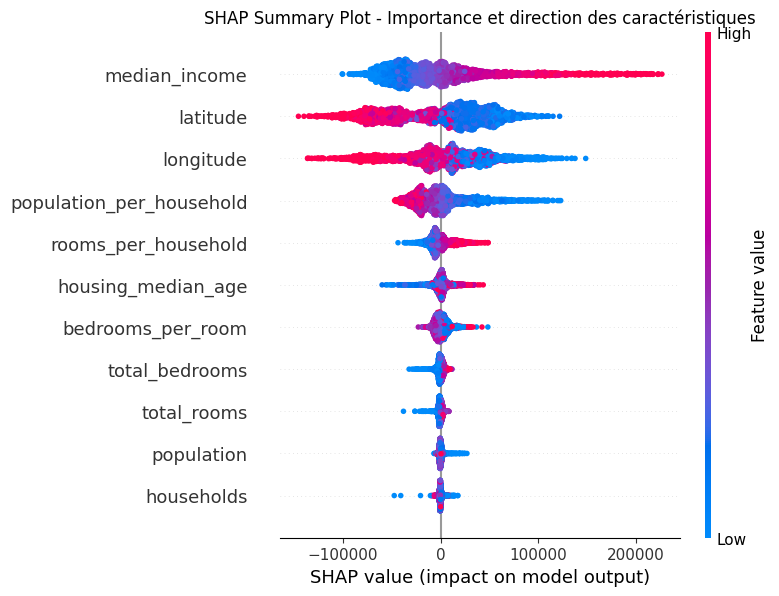

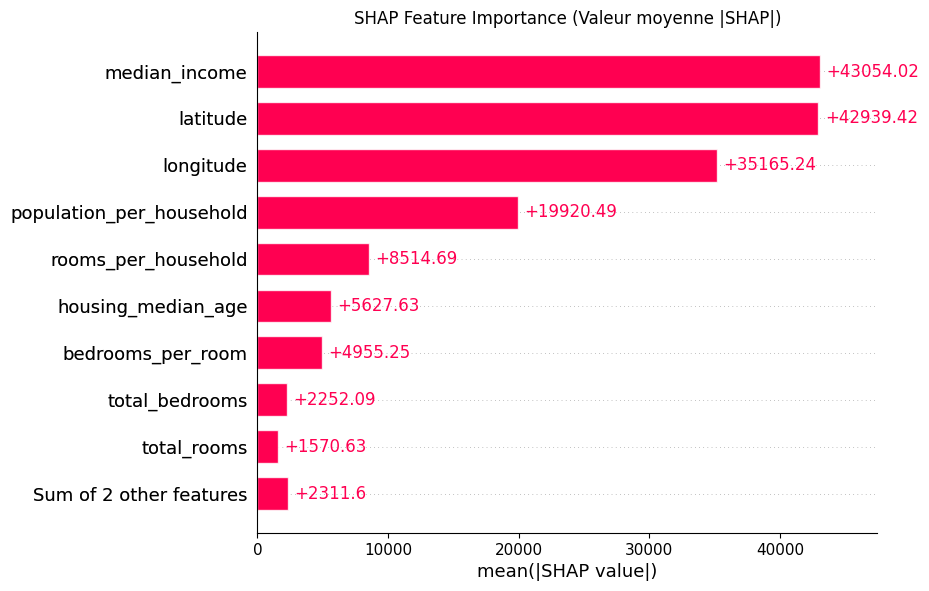

In [ ]:
# Calcul des valeurs SHAP via TreeExplainer
explainer = shap.TreeExplainer(best_lightgbm)
shap_values = explainer(X_val)

# Graphique 1 : Summary Plot (Distribution des impacts par variable)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_val, show=False)
plt.title("SHAP Summary Plot - Importance et direction des caractéristiques", fontsize=12)
plt.savefig("figures/04_shap_summary.png", bbox_inches='tight')
plt.show()

# Graphique 2 : Bar Plot (Importance globale des variables)
plt.figure(figsize=(10, 5))
shap.plots.bar(shap_values, show=False)
plt.title("SHAP Feature Importance (Valeur moyenne |SHAP|)")
plt.savefig("figures/05_shap_importance.png", bbox_inches='tight')
plt.show()

In [ ]:
# Évaluation finale sur le jeu de test indépendant
X_test = df_test_prepared.drop(columns=["median_house_value"])
y_test = df_test_prepared["median_house_value"]

test_predictions = best_lightgbm.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)

print(f"Performances Finales sur le Jeu de Test -> RMSE: {test_rmse:.2f} $ | R²: {test_r2:.4f}")

# Sauvegarde du modèle et du scaler avec joblib
joblib.dump(best_lightgbm, "results/best_lightgbm_model.pkl")
joblib.dump(scaler, "results/scaler.pkl")
print("Modèle et transformateur sauvegardés dans le dossier 'results/'.")

# Exportation du résumé des performances au format JSON
summary_metrics = {
    "Model_Name": "LightGBM Regressor (Optimized)",
    "Best_Hyperparameters": grid_search.best_params_,
    "Validation_RMSE": round(float(opt_rmse), 2),
    "Validation_R2": round(float(opt_r2), 4),
    "Test_RMSE": round(float(test_rmse), 2),
    "Test_R2": round(float(test_r2), 4)
}

with open("reports/final_summary.json", "w") as f:
    json.dump(summary_metrics, f, indent=4)

print("\nRapport final enregistré dans 'reports/final_summary.json' :")
print(json.dumps(summary_metrics, indent=4))

Performances Finales sur le Jeu de Test -> RMSE: 46265.19 $ | R²: 0.8327
Modèle et transformateur sauvegardés dans le dossier 'results/'.

Rapport final enregistré dans 'reports/final_summary.json' :
{
    "Model_Name": "LightGBM Regressor (Optimized)",
    "Best_Hyperparameters": {
        "learning_rate": 0.08,
        "max_depth": 10,
        "n_estimators": 200,
        "num_leaves": 63
    },
    "Validation_RMSE": 45510.39,
    "Validation_R2": 0.8497,
    "Test_RMSE": 46265.19,
    "Test_R2": 0.8327
}
